# EXP-15 – Decision Tree: Hyperparameter Tuning

## 1. Mục tiêu thí nghiệm

Thí nghiệm EXP-15 thực hiện tinh chỉnh các siêu tham số ảnh hưởng đến cấu trúc của thuật toán Decision Tree trên bộ dữ liệu Bank Marketing. Ba siêu tham số được khảo sát gồm `max_depth`, `min_samples_split` và `min_samples_leaf`.

Quá trình lựa chọn cấu hình sử dụng Stratified 5-Fold Cross-validation trên tập train, với F1-score làm tiêu chí tối ưu. Cấu hình có F1-score trung bình cao nhất trên các fold được chọn để huấn luyện mô hình cuối cùng và đánh giá trên tập test.

Các siêu tham số khác, bao gồm `class_weight="balanced"` và `random_state=42`, được giữ cố định theo EXP-03 để tập trung đánh giá ảnh hưởng của ba siêu tham số cấu trúc cây.

## 2. Phương pháp thực hiện

- Làm sạch dữ liệu, loại bỏ bản ghi trùng lặp và loại biến `duration` khỏi tập đặc trưng.
- Chia dữ liệu thành train/test theo tỷ lệ 80:20, phân tầng theo nhãn và sử dụng `random_state=42`.
- Đặt bộ tiền xử lý và Decision Tree trong cùng Pipeline. Trong mỗi fold, bộ tiền xử lý chỉ được fit trên phần train của fold tương ứng.
- Sử dụng GridSearchCV với StratifiedKFold 5-fold để khảo sát 12 tổ hợp `max_depth`, `min_samples_split` và `min_samples_leaf`.
- Chọn cấu hình có F1-score trung bình cao nhất trên Cross-validation; giữ ngưỡng phân loại mặc định 0,5 khi đánh giá trên test.
- So sánh kết quả EXP-15 với Decision Tree Baseline EXP-03 trên cùng tập test.

Không thực hiện SMOTE hoặc tối ưu threshold trong EXP-15; các yếu tố này thuộc những thí nghiệm riêng.

## 3. Thư viện và cấu hình đường dẫn

In [10]:
from pathlib import Path
from datetime import datetime
import sys
import json
import time

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay,
)


def find_project_root():
    """Tìm thư mục gốc dự án từ thư mục hiện tại hoặc các thư mục cha."""
    current = Path.cwd().resolve()
    for candidate in [current, *current.parents]:
        if (
            (candidate / "src" / "preprocessing.py").is_file()
            and (candidate / "data" / "raw" / "bank-additional-full.csv").is_file()
        ):
            return candidate
    raise FileNotFoundError(
        "Không tìm thấy thư mục gốc dự án. Hãy đặt notebook trong "
        "notebooks/Decision_Tree hoặc mở Jupyter từ thư mục gốc dự án."
    )


ROOT_DIR = find_project_root()
RAW_DATA_PATH = ROOT_DIR / "data" / "raw" / "bank-additional-full.csv"
RANDOM_STATE = 42
TEST_SIZE = 0.20
N_SPLITS = 5

if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

print("Project root:", ROOT_DIR)
print("Raw data:", RAW_DATA_PATH)
print("Python:", sys.version.split()[0])
print("Pandas:", pd.__version__)
print("Scikit-learn:", __import__("sklearn").__version__)

Project root: D:\#WS\Máy học\sgu2627k1_MayHoc\MayHoc_Nhom\Đồ án cuối kỳ
Raw data: D:\#WS\Máy học\sgu2627k1_MayHoc\MayHoc_Nhom\Đồ án cuối kỳ\data\raw\bank-additional-full.csv
Python: 3.15.0
Pandas: 3.1.0
Scikit-learn: 1.9.1


## 4. Đọc dữ liệu và chia tập train/test

Dữ liệu được đọc từ `data/raw/bank-additional-full.csv`. Các bản ghi trùng lặp và bản ghi thiếu nhãn được loại bỏ; biến mục tiêu `y` được mã hóa thành nhãn 0 và 1. Biến `duration` được loại khỏi tập đặc trưng.

Tập train và test được chia theo tỷ lệ 80:20, phân tầng theo nhãn và sử dụng `random_state=42` để bảo đảm cách chia nhất quán với các thí nghiệm trước.

In [11]:
df = pd.read_csv(RAW_DATA_PATH, sep=";")
df_model = df.drop_duplicates().dropna(subset=["y"]).copy()

X = df_model.drop(columns=["y", "duration"])
y = df_model["y"].map({"no": 0, "yes": 1})

if y.isna().any():
    invalid_labels = df_model.loc[y.isna(), "y"].unique().tolist()
    raise ValueError(f"Tồn tại nhãn mục tiêu chưa được ánh xạ: {invalid_labels}")

y = y.astype(int)

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y,
)

print("Toàn bộ dữ liệu sau làm sạch:", df_model.shape)
print("X_train_raw:", X_train_raw.shape)
print("X_test_raw:", X_test_raw.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)
print("Train class distribution:", y_train.value_counts().sort_index().to_dict())
print("Test class distribution:", y_test.value_counts().sort_index().to_dict())

display(pd.DataFrame({
    "Train": y_train.value_counts(normalize=True).sort_index(),
    "Test": y_test.value_counts(normalize=True).sort_index(),
}).rename(index={0: "no (0)", 1: "yes (1)"}).round(4))

Toàn bộ dữ liệu sau làm sạch: (41176, 21)
X_train_raw: (32940, 19)
X_test_raw: (8236, 19)
y_train: (32940,)
y_test: (8236,)
Train class distribution: {0: 29229, 1: 3711}
Test class distribution: {0: 7308, 1: 928}


,Train,Test
y,,
no (0),0.8873,0.8873
yes (1),0.1127,0.1127


### Nhận xét phân phối dữ liệu

Sau khi làm sạch, bộ dữ liệu gồm **41.176 bản ghi và 21 cột**. Tập train có **32.940 mẫu**, tập test có **8.236 mẫu**. Tỷ lệ lớp được giữ đồng nhất giữa hai tập: lớp `No` chiếm **88,73%**, lớp `Yes` chiếm **11,27%**.

Việc chia dữ liệu có phân tầng (`stratify=y`) giúp duy trì tỷ lệ hai lớp giữa train và test. Dữ liệu vẫn mất cân bằng đáng kể, do đó các chỉ số Precision, Recall và F1-score của lớp `Yes` cần được xem xét cùng với Accuracy.


## 5. Xây dựng Pipeline và tinh chỉnh siêu tham số

Bộ tiền xử lý gồm hai nhánh: đặc trưng số được điền giá trị thiếu bằng median và chuẩn hóa bằng StandardScaler; đặc trưng phân loại được điền giá trị thiếu bằng most_frequent và mã hóa One-Hot.

Pipeline được đưa trực tiếp vào GridSearchCV để bộ tiền xử lý được fit riêng bên trong từng fold. Grid tìm kiếm gồm 12 tổ hợp của ba siêu tham số cấu trúc cây, với 5 fold tương ứng 60 lượt fit.

In [12]:
numeric_features = X_train_raw.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X_train_raw.select_dtypes(exclude=["number"]).columns.tolist()

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, numeric_features),
        ("cat", categorical_pipeline, categorical_features),
    ],
)

# Các tham số cố định được giữ theo EXP-03.
dt_template = DecisionTreeClassifier(
    class_weight="balanced",
    random_state=RANDOM_STATE,
)

pipeline_dt = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", dt_template),
])

# Lưới có chứa cấu hình EXP-03 để đối chiếu trong quá trình tìm kiếm.
param_grid = {
    "classifier__max_depth": [4, 8, 12],
    "classifier__min_samples_split": [20, 40],
    "classifier__min_samples_leaf": [5, 10],
}

cv = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE,
)

n_candidates = (
    len(param_grid["classifier__max_depth"])
    * len(param_grid["classifier__min_samples_split"])
    * len(param_grid["classifier__min_samples_leaf"])
)
print("Số tổ hợp tham số:", n_candidates)
print("Số fold:", N_SPLITS)
print("Tổng số lượt fit dự kiến:", n_candidates * N_SPLITS)

search_dt = GridSearchCV(
    estimator=pipeline_dt,
    param_grid=param_grid,
    scoring={
        "f1": "f1",
        "precision": "precision",
        "recall": "recall",
        "roc_auc": "roc_auc",
    },
    refit="f1",
    cv=cv,
    n_jobs=1,
    verbose=1,
    error_score="raise",
    return_train_score=False,
)

start_time = time.perf_counter()
search_dt.fit(X_train_raw, y_train)
elapsed_seconds = time.perf_counter() - start_time

print(f"Thời gian tìm kiếm: {elapsed_seconds:.2f} giây ({elapsed_seconds / 60:.2f} phút)")
print("Tham số tốt nhất:", search_dt.best_params_)
print(f"F1-score CV tốt nhất: {search_dt.best_score_:.4f}")

Số tổ hợp tham số: 12
Số fold: 5
Tổng số lượt fit dự kiến: 60
Fitting 5 folds for each of 12 candidates, totalling 60 fits
Thời gian tìm kiếm: 12.95 giây (0.22 phút)
Tham số tốt nhất: {'classifier__max_depth': 4, 'classifier__min_samples_leaf': 5, 'classifier__min_samples_split': 20}
F1-score CV tốt nhất: 0.4633


## 6. Kết quả tìm kiếm và cấu hình tốt nhất

In [13]:
cv_results = pd.DataFrame(search_dt.cv_results_)
cv_summary_columns = [
    "rank_test_f1",
    "mean_test_f1",
    "std_test_f1",
    "mean_test_precision",
    "mean_test_recall",
    "mean_test_roc_auc",
    "params",
]

cv_results_sorted = cv_results.sort_values(
    ["rank_test_f1", "mean_test_f1"],
    ascending=[True, False],
).reset_index(drop=True)

print("Top 10 tổ hợp tham số theo F1-score Cross-validation:")
display(cv_results_sorted[cv_summary_columns].head(10).round(4))

best_params_readable = {
    key.replace("classifier__", ""): value
    for key, value in search_dt.best_params_.items()
}
print("\nCấu hình Decision Tree tốt nhất:")
for name, value in best_params_readable.items():
    print(f"{name}: {value}")
print(f"F1-score trung bình 5-fold: {search_dt.best_score_:.4f}")

Top 10 tổ hợp tham số theo F1-score Cross-validation:


,rank_test_f1,mean_test_f1,std_test_f1,mean_test_precision,mean_test_recall,mean_test_roc_auc,params
0,1,0.4633,0.0134,0.3830,0.5869,0.7747,"{'classifier__max_depth': 4, 'classifier__min_..."
1,1,0.4633,0.0134,0.3830,0.5869,0.7747,"{'classifier__max_depth': 4, 'classifier__min_..."
2,3,0.4627,0.0139,0.3824,0.5864,0.7747,"{'classifier__max_depth': 4, 'classifier__min_..."
3,3,0.4627,0.0139,0.3824,0.5864,0.7747,"{'classifier__max_depth': 4, 'classifier__min_..."
4,5,0.4424,0.0055,0.3431,0.6236,0.7762,"{'classifier__max_depth': 8, 'classifier__min_..."
5,6,0.4421,0.0052,0.3423,0.6249,0.7763,"{'classifier__max_depth': 8, 'classifier__min_..."
6,7,0.4415,0.0064,0.3420,0.6236,0.7727,"{'classifier__max_depth': 8, 'classifier__min_..."
7,8,0.4415,0.0059,0.3423,0.6222,0.7713,"{'classifier__max_depth': 8, 'classifier__min_..."
8,9,0.4278,0.0091,0.3304,0.6095,0.7628,"{'classifier__max_depth': 12, 'classifier__min..."
9,10,0.4252,0.0120,0.3314,0.5958,0.7529,"{'classifier__max_depth': 12, 'classifier__min..."



Cấu hình Decision Tree tốt nhất:
max_depth: 4
min_samples_leaf: 5
min_samples_split: 20
F1-score trung bình 5-fold: 0.4633


### Nhận xét kết quả tìm kiếm siêu tham số

GridSearchCV lựa chọn cấu hình `max_depth=4`, `min_samples_leaf=5` và `min_samples_split=20`, với F1-score trung bình 5-fold đạt **0,4633**. Trong phạm vi 12 tổ hợp được khảo sát, đây là cấu hình có F1-score Cross-validation cao nhất.

Cấu hình được chọn có `max_depth=4`, thấp hơn độ sâu 8 của EXP-03, trong khi `min_samples_leaf=5` và `min_samples_split=20` được giữ theo một tổ hợp trong lưới tìm kiếm. Kết quả này cho thấy cấu hình cây nông hơn đạt điểm F1 trung bình CV tốt nhất trong các cấu hình đã thử.


## 7. Huấn luyện mô hình tốt nhất và đánh giá trên tập test

GridSearchCV refit cấu hình tốt nhất trên toàn bộ tập train. Mô hình được đánh giá trên tập test bằng ngưỡng phân loại mặc định 0,5. Các chỉ số gồm Accuracy, Precision, Recall, F1-score và ROC-AUC.

In [14]:
def calculate_metrics(y_true, y_pred, y_probability):
    return {
        "Accuracy": float(accuracy_score(y_true, y_pred)),
        "Precision": float(precision_score(y_true, y_pred, zero_division=0)),
        "Recall": float(recall_score(y_true, y_pred, zero_division=0)),
        "F1-score": float(f1_score(y_true, y_pred, zero_division=0)),
        "ROC-AUC": float(roc_auc_score(y_true, y_probability)),
    }

# Mô hình tuned đã được GridSearchCV refit trên toàn bộ tập train.
model_dt_tuned = search_dt.best_estimator_

positive_class_index = list(model_dt_tuned.classes_).index(1)
y_test_array = np.asarray(y_test).ravel()

y_probability_tuned = model_dt_tuned.predict_proba(X_test_raw)[:, positive_class_index]
y_prediction_tuned = model_dt_tuned.predict(X_test_raw)
tuned_metrics = calculate_metrics(
    y_test_array,
    y_prediction_tuned,
    y_probability_tuned,
)

# Huấn luyện lại cấu hình EXP-03 trên cùng Pipeline và cùng tập dữ liệu để làm mốc đối chiếu.
baseline_pipeline = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("classifier", DecisionTreeClassifier(
        max_depth=8,
        min_samples_split=20,
        min_samples_leaf=10,
        class_weight="balanced",
        random_state=RANDOM_STATE,
    )),
])
baseline_pipeline.fit(X_train_raw, y_train)
y_probability_baseline = baseline_pipeline.predict_proba(X_test_raw)[:, 1]
y_prediction_baseline = baseline_pipeline.predict(X_test_raw)
baseline_metrics = calculate_metrics(
    y_test_array,
    y_prediction_baseline,
    y_probability_baseline,
)

print("EXP-03 – Decision Tree Baseline:")
display(pd.DataFrame([baseline_metrics], index=["EXP-03"]).round(4))

print("EXP-15 – Decision Tree Tuned:")
display(pd.DataFrame([tuned_metrics], index=["EXP-15"]).round(4))

print("\nClassification report – EXP-15:")
print(classification_report(
    y_test_array,
    y_prediction_tuned,
    labels=[0, 1],
    target_names=["No", "Yes"],
    zero_division=0,
))

EXP-03 – Decision Tree Baseline:


,Accuracy,Precision,Recall,F1-score,ROC-AUC
EXP-03,0.8263,0.353,0.6509,0.4577,0.7932


EXP-15 – Decision Tree Tuned:


,Accuracy,Precision,Recall,F1-score,ROC-AUC
EXP-15,0.846,0.3859,0.6196,0.4756,0.7866



Classification report – EXP-15:
              precision    recall  f1-score   support

          No       0.95      0.87      0.91      7308
         Yes       0.39      0.62      0.48       928

    accuracy                           0.85      8236
   macro avg       0.67      0.75      0.69      8236
weighted avg       0.88      0.85      0.86      8236



### Nhận xét kết quả đánh giá trên tập test

Với cấu hình tốt nhất từ GridSearchCV và ngưỡng phân loại mặc định 0,5, EXP-15 đạt Accuracy **0,8460**, Precision **0,3859**, Recall **0,6196**, F1-score **0,4756** và ROC-AUC **0,7866**.

Theo Classification Report, lớp `No` đạt Precision **0,95**, Recall **0,87** và F1-score **0,91** trên 7.308 mẫu. Lớp `Yes` đạt Precision **0,39**, Recall **0,62** và F1-score **0,48** trên 928 mẫu. Do lớp `No` chiếm đa số, Weighted Average cao hơn Macro Average; vì vậy cần xem riêng các chỉ số của lớp `Yes` thay vì chỉ dựa vào Accuracy hoặc Weighted Average.


## 8. Biểu đồ đánh giá mô hình

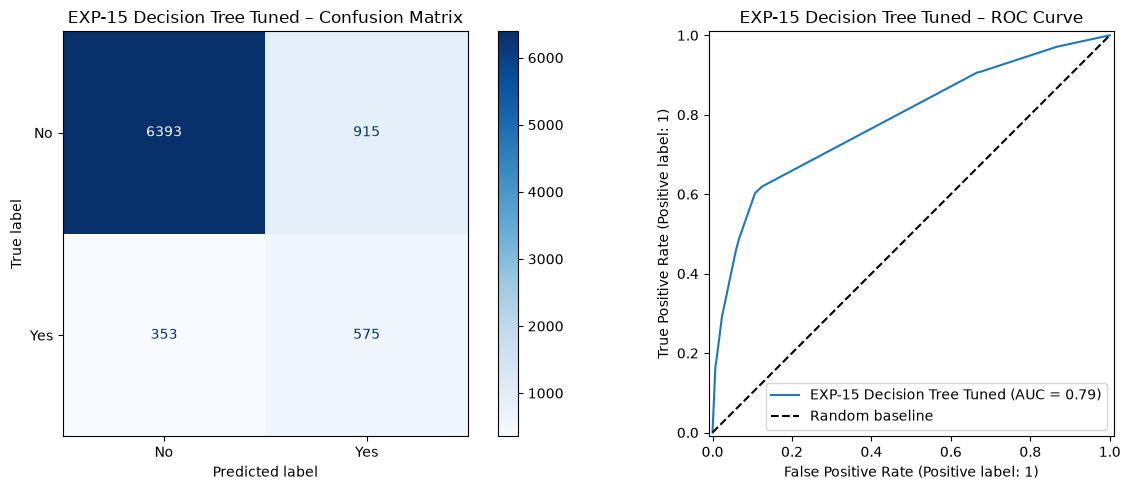

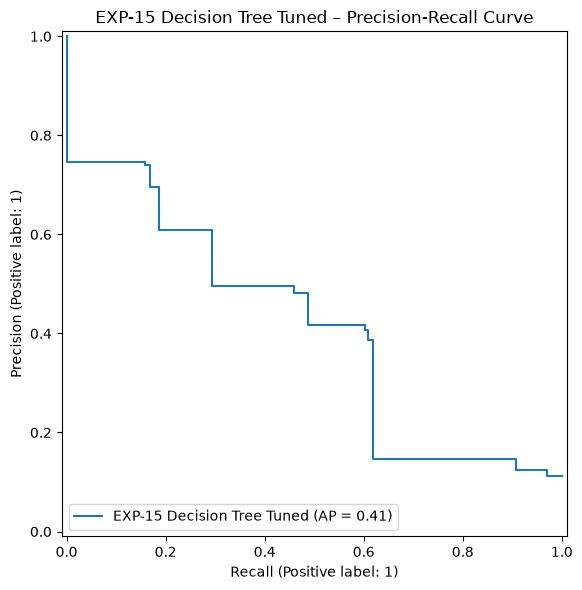

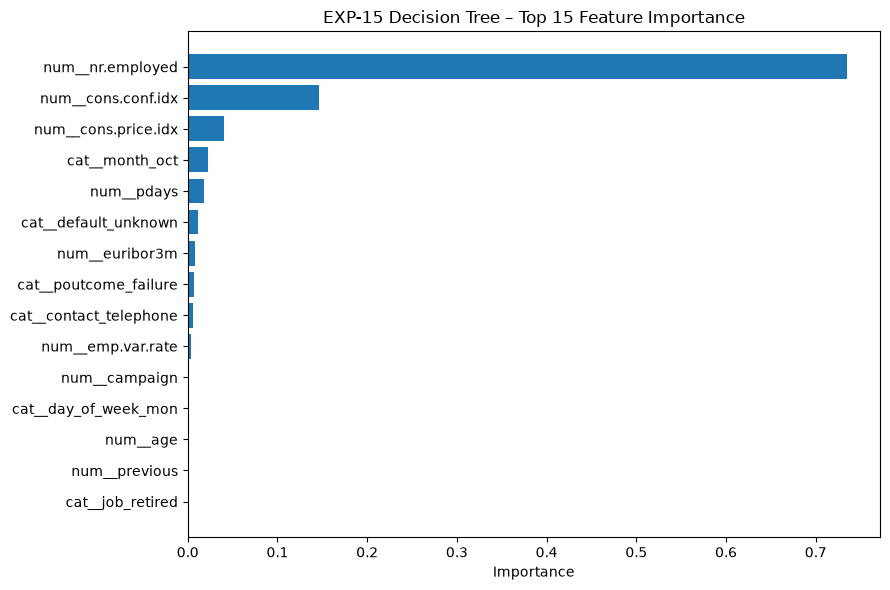

,Feature,Importance
0,num__nr.employed,0.734868
1,num__cons.conf.idx,0.146585
2,num__cons.price.idx,0.040234
3,cat__month_oct,0.022811
4,num__pdays,0.017930
5,cat__default_unknown,0.011774
6,num__euribor3m,0.008413
7,cat__poutcome_failure,0.007537
8,cat__contact_telephone,0.005524
9,num__emp.var.rate,0.003484


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test_array,
    y_prediction_tuned,
    labels=[0, 1],
    display_labels=["No", "Yes"],
    cmap="Blues",
    ax=axes[0],
    values_format="d",
)
axes[0].set_title("EXP-15 Decision Tree Tuned – Confusion Matrix")

RocCurveDisplay.from_predictions(
    y_test_array,
    y_probability_tuned,
    name="EXP-15 Decision Tree Tuned",
    ax=axes[1],
)
axes[1].plot([0, 1], [0, 1], "k--", label="Random baseline")
axes[1].set_title("EXP-15 Decision Tree Tuned – ROC Curve")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 6))
PrecisionRecallDisplay.from_predictions(
    y_test_array,
    y_probability_tuned,
    name="EXP-15 Decision Tree Tuned",
    ax=ax,
)
ax.set_title("EXP-15 Decision Tree Tuned – Precision-Recall Curve")
plt.tight_layout()
plt.show()

# Top 15 đặc trưng theo Feature Importance của cây sau tinh chỉnh.
feature_names = model_dt_tuned.named_steps["preprocessor"].get_feature_names_out()
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": model_dt_tuned.named_steps["classifier"].feature_importances_,
}).sort_values("Importance", ascending=False).reset_index(drop=True)

top_features = feature_importance.head(15).sort_values("Importance", ascending=True)
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top_features["Feature"], top_features["Importance"])
ax.set_title("EXP-15 Decision Tree – Top 15 Feature Importance")
ax.set_xlabel("Importance")
plt.tight_layout()
plt.show()

display(feature_importance.head(15).round(6))

### Nhận xét biểu đồ và đặc trưng

**Confusion Matrix:** Với 928 trường hợp đăng ký thực tế, mô hình nhận diện đúng **575** trường hợp và bỏ sót **353** trường hợp. Trong 7.308 trường hợp không đăng ký, mô hình dự đoán đúng **6.393** trường hợp và dự đoán nhầm **915** trường hợp là có đăng ký. Kết quả này phù hợp với Recall **0,6196** và Precision **0,3859**: mô hình nhận diện được khoảng 61,96% khách hàng đăng ký, nhưng số dự đoán dương tính sai vẫn còn đáng kể.

**ROC Curve:** ROC-AUC đạt **0,7866**, thấp hơn mức **0,7932** của EXP-03. Điều này cho thấy khả năng phân biệt hai lớp xét trên các ngưỡng xác suất giảm nhẹ sau khi tinh chỉnh; cải thiện F1-score tại ngưỡng 0,5 không đồng nghĩa ROC-AUC cũng tăng.

**Precision-Recall Curve:** Tại ngưỡng mặc định 0,5, mô hình đạt Precision **0,3859** và Recall **0,6196**. Mô hình nhận diện được một phần đáng kể khách hàng đăng ký, nhưng phải đánh đổi bằng số lượng dự đoán dương tính sai. Đặc điểm này cần được xem xét trong bối cảnh lớp `Yes` chỉ chiếm **11,27%** dữ liệu.

**Feature Importance:** `num__nr.employed` là đặc trưng quan trọng nhất với mức **0,734868**, tiếp theo là `num__cons.conf.idx` (**0,146585**) và `num__cons.price.idx` (**0,040234**). Ba đặc trưng đầu chiếm khoảng **92,17%** tổng Feature Importance của cây. Các đặc trưng còn lại có mức đóng góp nhỏ hơn đáng kể; một số đặc trưng trong Top 15 có Importance bằng 0. Đây là mức đóng góp theo cấu trúc cây đã huấn luyện, không phải bằng chứng rằng các biến này có quan hệ nhân quả với quyết định đăng ký.


## 9. Lưu kết quả thí nghiệm tự động

Mỗi lần chạy notebook tạo một thư mục kết quả riêng theo thời gian thực hiện. Kết quả gồm cấu hình tìm kiếm, toàn bộ kết quả Cross-validation, các chỉ số đánh giá, dự đoán trên tập test, mô hình Pipeline và biểu đồ.

In [16]:
RUN_ID = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
RESULTS_ROOT = ROOT_DIR / "notebooks" / "02_EDA" / "Experiments" / "Logs"
EXP15_ROOT = RESULTS_ROOT / "Experiment_15_DecisionTree_tuned"
RUN_DIR = EXP15_ROOT / f"run_{RUN_ID}"
RUN_DIR.mkdir(parents=True, exist_ok=False)

experiment_params = {
    "experiment": "EXP-15 Decision Tree Hyperparameter Tuning",
    "model": "DecisionTreeClassifier",
    "fixed_parameters": {
        "class_weight": "balanced",
        "random_state": RANDOM_STATE,
    },
    "param_grid": param_grid,
    "best_params": best_params_readable,
    "best_cv_f1": float(search_dt.best_score_),
    "cross_validation": {
        "method": "StratifiedKFold",
        "n_splits": N_SPLITS,
        "shuffle": True,
        "random_state": RANDOM_STATE,
        "scoring": ["f1", "precision", "recall", "roc_auc"],
        "refit": "f1",
    },
    "train_test_split": {
        "test_size": TEST_SIZE,
        "random_state": RANDOM_STATE,
        "stratify": True,
    },
    "preprocessing": {
        "numeric": ["SimpleImputer(median)", "StandardScaler"],
        "categorical": ["SimpleImputer(most_frequent)", "OneHotEncoder(handle_unknown=ignore)"],
        "inside_cross_validation_pipeline": True,
    },
    "threshold": 0.5,
    "elapsed_seconds": float(elapsed_seconds),
}

with open(RUN_DIR / "params_cfg.json", "w", encoding="utf-8") as file:
    json.dump(experiment_params, file, ensure_ascii=False, indent=2, default=str)

with open(RUN_DIR / "metrics.json", "w", encoding="utf-8") as file:
    json.dump(tuned_metrics, file, ensure_ascii=False, indent=2)

pd.DataFrame([tuned_metrics]).to_csv(RUN_DIR / "metrics.csv", index=False)
cv_results.to_csv(RUN_DIR / "cv_results_all.csv", index=False)
cv_results_sorted[cv_summary_columns].head(20).to_csv(
    RUN_DIR / "cv_results_top20.csv",
    index=False,
)

pd.DataFrame({
    "y_true": y_test_array,
    "y_pred_baseline": np.asarray(y_prediction_baseline).ravel(),
    "y_probability_baseline": np.asarray(y_probability_baseline).ravel(),
    "y_pred_tuned": np.asarray(y_prediction_tuned).ravel(),
    "y_probability_tuned": np.asarray(y_probability_tuned).ravel(),
}).to_csv(RUN_DIR / "predictions.csv", index=False)

feature_importance.to_csv(RUN_DIR / "feature_importance.csv", index=False)
joblib.dump(model_dt_tuned, RUN_DIR / "best_model.pkl")

comparison_for_save = pd.DataFrame([
    {"Model": "EXP-03 – Decision Tree Baseline", **baseline_metrics},
    {"Model": "EXP-15 – Decision Tree Tuned", **tuned_metrics},
])
comparison_for_save.to_csv(RUN_DIR / "comparison_exp03_exp15.csv", index=False)

# Lưu biểu đồ Confusion Matrix và ROC Curve.
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test_array,
    y_prediction_tuned,
    labels=[0, 1],
    display_labels=["No", "Yes"],
    cmap="Blues",
    ax=axes[0],
    values_format="d",
)
axes[0].set_title("EXP-15 Confusion Matrix")
RocCurveDisplay.from_predictions(
    y_test_array,
    y_probability_tuned,
    name="EXP-15 Decision Tree Tuned",
    ax=axes[1],
)
axes[1].plot([0, 1], [0, 1], "k--")
axes[1].set_title("EXP-15 ROC Curve")
axes[1].legend(loc="lower right")
fig.tight_layout()
fig.savefig(RUN_DIR / "confusion_roc.png", dpi=150, bbox_inches="tight")
plt.close(fig)

# Lưu biểu đồ Feature Importance.
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top_features["Feature"], top_features["Importance"])
ax.set_title("EXP-15 Top 15 Feature Importance")
ax.set_xlabel("Importance")
fig.tight_layout()
fig.savefig(RUN_DIR / "feature_importance.png", dpi=150, bbox_inches="tight")
plt.close(fig)

print("EXP-15 results saved to:", RUN_DIR)
print("Files created:")
for output_path in sorted(RUN_DIR.iterdir()):
    if output_path.is_file():
        print("-", output_path.name)

EXP-15 results saved to: D:\#WS\Máy học\sgu2627k1_MayHoc\MayHoc_Nhom\Đồ án cuối kỳ\notebooks\02_EDA\Experiments\Logs\Experiment_15_DecisionTree_tuned\run_20261127_173930_374522
Files created:
- best_model.pkl
- comparison_exp03_exp15.csv
- confusion_roc.png
- cv_results_all.csv
- cv_results_top20.csv
- feature_importance.csv
- feature_importance.png
- metrics.csv
- metrics.json
- params_cfg.json
- predictions.csv


## 10. So sánh EXP-03 và EXP-15

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,EXP-03 – Decision Tree Baseline,0.8263,0.3530,0.6509,0.4577,0.7932
1,EXP-15 – Decision Tree Tuned,0.8460,0.3859,0.6196,0.4756,0.7866


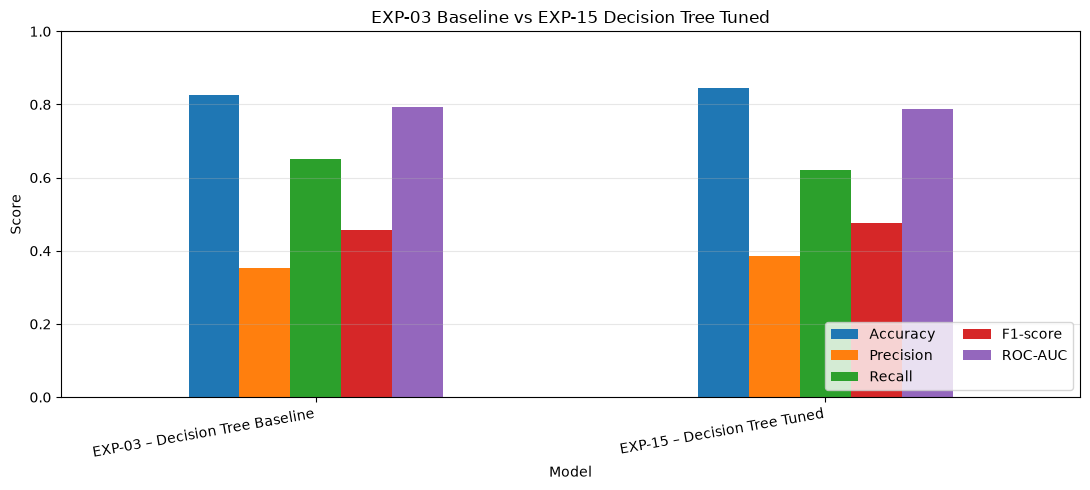

In [17]:
comparison_df = pd.DataFrame([
    {"Model": "EXP-03 – Decision Tree Baseline", **baseline_metrics},
    {"Model": "EXP-15 – Decision Tree Tuned", **tuned_metrics},
])

display(comparison_df.round(4))
comparison_df.to_csv(RUN_DIR / "comparison_exp03_exp15.csv", index=False)

metric_columns = ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]
ax = comparison_df.set_index("Model")[metric_columns].plot(
    kind="bar",
    figsize=(11, 5),
)
ax.set_title("EXP-03 Baseline vs EXP-15 Decision Tree Tuned")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.grid(axis="y", alpha=0.3)
plt.xticks(rotation=10, ha="right")
plt.legend(loc="lower right", ncol=2)
plt.tight_layout()
plt.show()

### Nhận xét so sánh EXP-03 và EXP-15

So với Decision Tree Baseline EXP-03, mô hình EXP-15 cải thiện Accuracy từ **0,8263** lên **0,8460**, Precision từ **0,3530** lên **0,3859** và F1-score từ **0,4577** lên **0,4756**. Mức tăng F1-score là **0,0179**.

Ở chiều ngược lại, Recall giảm từ **0,6509** xuống **0,6196**, còn ROC-AUC giảm từ **0,7932** xuống **0,7866**. Vì vậy, cấu hình tuned tạo ra sự cải thiện vừa phải về F1-score và Precision, nhưng không duy trì được mức Recall và ROC-AUC của baseline.

Kết quả cho thấy việc điều chỉnh `max_depth`, `min_samples_split` và `min_samples_leaf` đã thay đổi sự cân bằng giữa nhận diện đúng lớp `Yes` và hạn chế dự đoán nhầm. Cấu hình được chọn là `max_depth=4`, `min_samples_leaf=5`, `min_samples_split=20`, với F1-score Cross-validation **0,4633** và F1-score trên test **0,4756**.


## 11. Bảng kết quả tổng hợp

In [18]:
print("Best parameters:")
print(best_params_readable)
print(f"\nBest 5-fold CV F1-score: {search_dt.best_score_:.4f}")
print(f"Search time: {elapsed_seconds:.2f} seconds")
print("\nTest metrics:")
display(pd.DataFrame([tuned_metrics], index=["EXP-15 – Decision Tree Tuned"]).round(4))
print("\nOutput directory:")
print(RUN_DIR)

Best parameters:
{'max_depth': 4, 'min_samples_leaf': 5, 'min_samples_split': 20}

Best 5-fold CV F1-score: 0.4633
Search time: 12.95 seconds

Test metrics:


,Accuracy,Precision,Recall,F1-score,ROC-AUC
EXP-15 – Decision Tree Tuned,0.846,0.3859,0.6196,0.4756,0.7866



Output directory:
D:\#WS\Máy học\sgu2627k1_MayHoc\MayHoc_Nhom\Đồ án cuối kỳ\notebooks\02_EDA\Experiments\Logs\Experiment_15_DecisionTree_tuned\run_20261127_173930_374522


### Kết luận EXP-15

GridSearchCV lựa chọn cấu hình Decision Tree gồm `max_depth=4`, `min_samples_leaf=5` và `min_samples_split=20`, đạt F1-score trung bình 5-fold **0,4633**. Khi đánh giá trên tập test với threshold mặc định 0,5, mô hình đạt F1-score **0,4756** và ROC-AUC **0,7866**.

So với EXP-03, EXP-15 tăng Accuracy, Precision và F1-score, trong đó F1-score tăng **0,0179**. Tuy nhiên, Recall và ROC-AUC giảm. Do đó, kết quả tuning thể hiện sự cải thiện về F1-score và Precision trên tập test, nhưng mức cải thiện còn vừa phải và đi kèm sự suy giảm Recall.

Trong cấu hình được chọn, `num__nr.employed` chiếm tỷ trọng Feature Importance lớn nhất (**0,734868**), cho thấy mô hình dựa nhiều vào đặc trưng này khi phân chia dữ liệu. EXP-15 hoàn thành mục tiêu khảo sát ảnh hưởng của ba siêu tham số cấu trúc cây trong phạm vi lưới tìm kiếm đã thiết lập.
